# CNN Architectures - Image Classification

**Chu de:** So sanh LeNet-5, AlexNet, VGG-16 va ResNet-18 tren bai toan phan loai Cho vs Meo

**Dataset:** Cats vs Dogs - anh RGB

**Muc tieu:** Hieu va so sanh 4 kien truc CNN kinh dien tren cung mot bai toan

In [1]:
# So sánh validation curves của tất cả model đã train
hist_map = {
    "lenet":   OUT_DIR / "metrics" / "lenet_history.json",
    "alexnet": OUT_DIR / "metrics" / "alexnet_history.json",
    "vgg16":   OUT_DIR / "metrics" / "vgg16_history.json",
    "resnet18":OUT_DIR / "metrics" / "resnet18_history.json",
}
# Chỉ đưa vào những model đã có history
hist_avail = {k: v for k, v in hist_map.items() if Path(v).exists()}

compare_all_models_plot(
    history_paths=hist_avail,
    output_path=OUT_DIR / "figures" / "comparison_all_models.png",
)

Device   : cuda
LeNet-5  : 61,326 params
ResNet-18: 11,177,538 params


---
## 1. Dataset <a id='1-dataset'></a>

,cats,dogs,total
train,8002,7990,15992
val,2001,1998,3999
test,2500,2500,5000


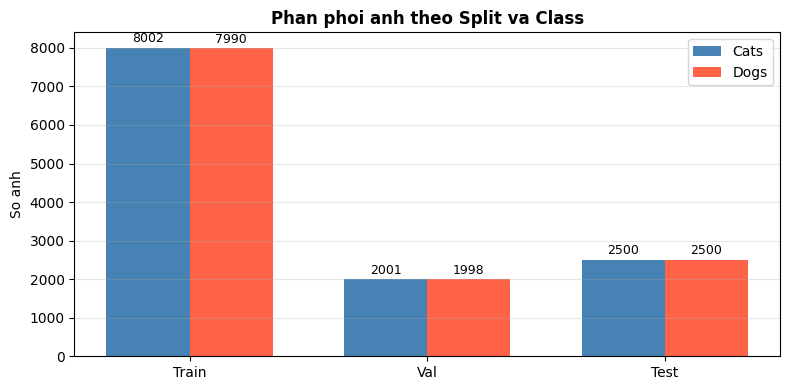

In [2]:
splits  = ["train", "val", "test"]
classes = ["cats", "dogs"]
counts = {}
for sp in splits:
    counts[sp] = {cl: len(list((DATA_DIR / sp / cl).glob("*.jpg"))) for cl in classes}

df_counts = pd.DataFrame(counts).T
df_counts["total"] = df_counts.sum(axis=1)
display(
    df_counts.style
    .set_caption("Phan phoi dataset (so anh)")
    .highlight_max(axis=0, color="green")
)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(splits))
w = 0.35
b1 = ax.bar(x - w/2, [counts[s]["cats"] for s in splits], w, label="Cats", color="steelblue")
b2 = ax.bar(x + w/2, [counts[s]["dogs"] for s in splits], w, label="Dogs", color="tomato")
ax.set_xticks(x)
ax.set_xticklabels([s.capitalize() for s in splits])
ax.set_ylabel("So anh")
ax.set_title("Phan phoi anh theo Split va Class", fontweight="bold")
ax.legend()
ax.grid(axis="y", alpha=0.3)
for bar in list(b1) + list(b2):
    h = int(bar.get_height())
    ax.annotate(
        str(h),
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 4), textcoords="offset points",
        ha="center", fontsize=9,
    )
plt.tight_layout()
plt.show()



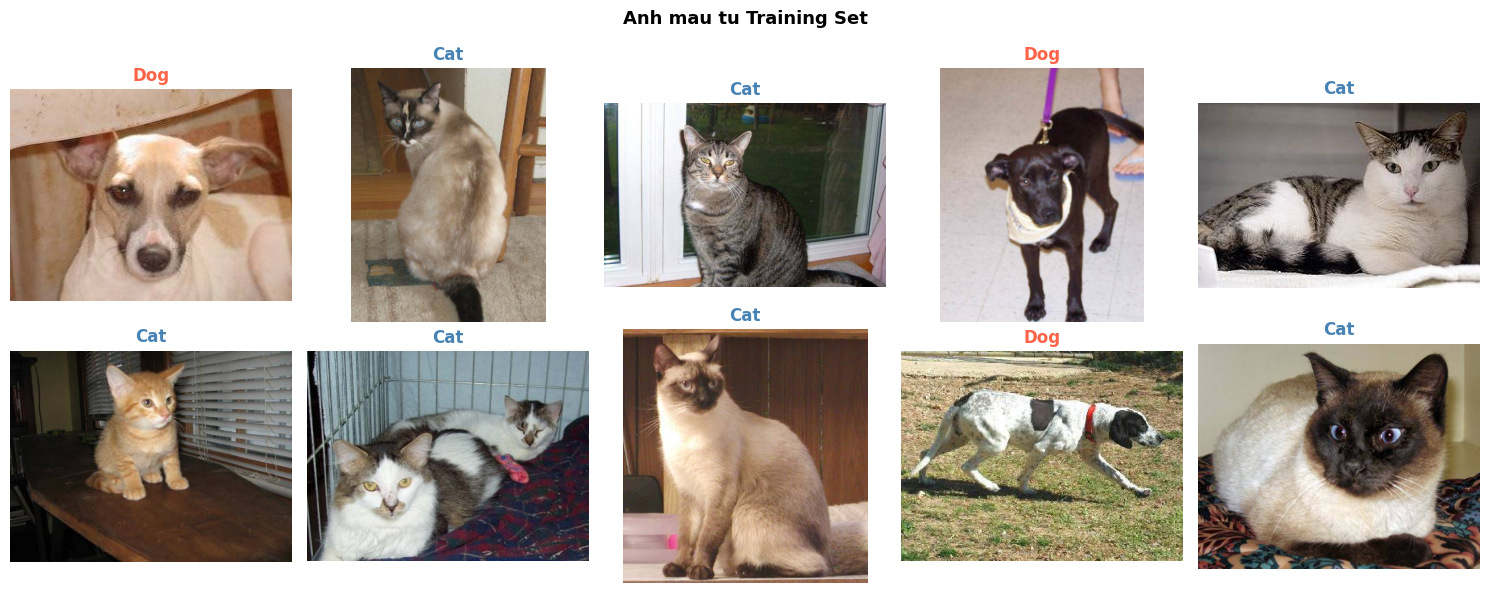

In [3]:
ds_train   = CatsDogsDataset(DATA_DIR, "train")
sample_idx = random.sample(range(len(ds_train)), 10)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
fig.suptitle("Anh mau tu Training Set", fontsize=13, fontweight="bold")
for i, idx in enumerate(sample_idx):
    path, label = ds_train.samples[idx]
    ax = axes[i // 5][i % 5]
    ax.imshow(Image.open(path))
    ax.axis("off")
    ax.set_title(
        "Cat" if label == 0 else "Dog",
        color="steelblue" if label == 0 else "tomato",
        fontweight="bold",
    )
plt.tight_layout()
plt.show()

---
## 2. Kien truc LeNet-5 <a id='2-lenet'></a>

LeNet-5 (LeCun, 1998) - mang CNN kinh dien, thiet ke cho nhan dang chu so viet tay.
O day ta ap dung cho bai toan phan loai anh mau 32x32.

In [4]:
lenet_model = build_lenet(num_classes=2)
print(lenet_model)
print("Tong so tham so:", format(n_lenet, ','))

LeNet(
  (features): Sequential(
    (0): Conv2d(3, 6, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=400, out_features=120, bias=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=120, out_features=84, bias=True)
    (4): ReLU(inplace=True)
    (5): Linear(in_features=84, out_features=2, bias=True)
  )
)
Tong so tham so: 61,326


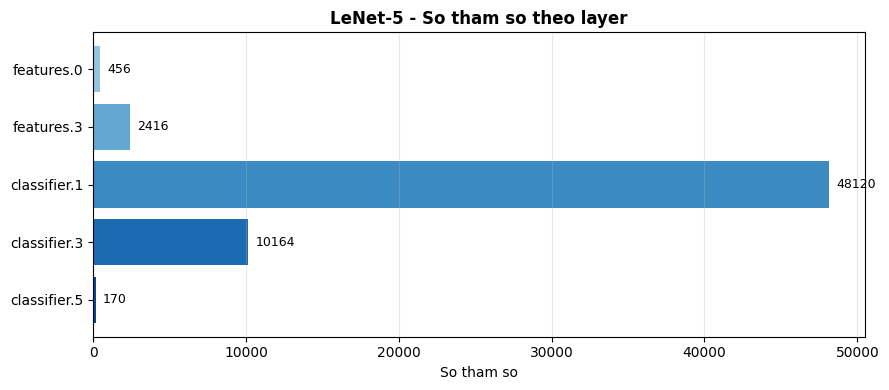

In [5]:
layer_groups = {}
for name, module in lenet_model.named_modules():
    if len(list(module.children())) == 0:
        n = sum(p.numel() for p in module.parameters())
        if n > 0:
            layer_groups[name if name else "root"] = n

labels = list(layer_groups.keys())
sizes  = list(layer_groups.values())

fig, ax = plt.subplots(figsize=(9, 4))
colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(labels)))
bars = ax.barh(labels, sizes, color=colors)
for bar, v in zip(bars, sizes):
    ax.text(
        bar.get_width() + max(sizes) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        str(v), va="center", fontsize=9,
    )
ax.set_xlabel("So tham so")
ax.set_title("LeNet-5 - So tham so theo layer", fontweight="bold")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

---
## 3. Kien truc AlexNet <a id='3-alexnet'></a>

AlexNet (Krizhevsky et al., 2012) - chien thang ImageNet ILSVRC 2012, danh dau buoc ngoat cua Deep Learning.
Su dung 5 lop Conv + 3 lop FC, dropout va ReLU.

In [ ]:
alexnet_model = build_alexnet(num_classes=2)
print(alexnet_model)
print("Tong so tham so:", format(n_alexnet, ','))

In [ ]:
layer_groups_a = {}
for name, module in alexnet_model.named_modules():
    if len(list(module.children())) == 0:
        n = sum(p.numel() for p in module.parameters())
        if n > 0:
            layer_groups_a[name if name else "root"] = n

labels_a = list(layer_groups_a.keys())
sizes_a  = list(layer_groups_a.values())

fig, ax = plt.subplots(figsize=(9, 5))
colors_a = plt.cm.Greens(np.linspace(0.4, 0.9, len(labels_a)))
bars = ax.barh(labels_a, sizes_a, color=colors_a)
for bar, v in zip(bars, sizes_a):
    ax.text(
        bar.get_width() + max(sizes_a) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{v:,}", va="center", fontsize=9,
    )
ax.set_xlabel("So tham so")
ax.set_title("AlexNet - So tham so theo layer", fontweight="bold")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

---
## 4. Kien truc VGG-16 <a id='4-vgg16'></a>

VGG-16 (Simonyan & Zisserman, 2014) - su dung chi conv 3x3 nho nhung xep nhieu lop.
13 lop Conv + 3 lop FC, chung minh rang do sau mang quan trong hon kich thuoc filter.

In [ ]:
vgg_model = build_vgg16(num_classes=2)
print(vgg_model)
print("Tong so tham so:", format(n_vgg16, ','))

In [ ]:
layer_groups_v = {}
for name, module in vgg_model.named_modules():
    if len(list(module.children())) == 0:
        n = sum(p.numel() for p in module.parameters())
        if n > 0:
            layer_groups_v[name if name else "root"] = n

labels_v = list(layer_groups_v.keys())
sizes_v  = list(layer_groups_v.values())

fig, ax = plt.subplots(figsize=(10, 7))
colors_v = plt.cm.Oranges(np.linspace(0.4, 0.9, len(labels_v)))
bars = ax.barh(labels_v, sizes_v, color=colors_v)
for bar, v in zip(bars, sizes_v):
    ax.text(
        bar.get_width() + max(sizes_v) * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f"{v:,}", va="center", fontsize=8,
    )
ax.set_xlabel("So tham so")
ax.set_title("VGG-16 - So tham so theo layer", fontweight="bold")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

---
## 5. Kien truc ResNet-18 <a id='5-resnet'></a>

ResNet-18 (He et al., 2016) - gioi thieu **Residual Connection** (skip connection)
de giai quyet van de vanishing gradient, cho phep train mang rat sau hieu qua.

In [6]:
resnet_model = build_resnet18(num_classes=2)
print(resnet_model)
print("Tong so tham so:", format(n_resnet, ','))

ResNet18(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  )
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_runni

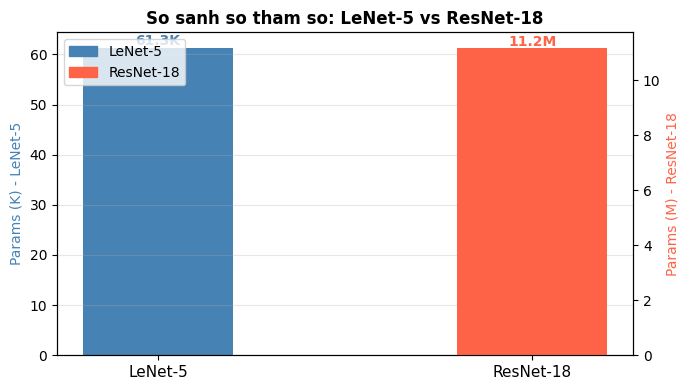

In [7]:
MODEL_NAMES = ["LeNet-5", "AlexNet", "VGG-16", "ResNet-18"]
MODEL_PARAMS = [n_lenet, n_alexnet, n_vgg16, n_resnet]
COLORS_BAR   = ["steelblue", "seagreen", "darkorange", "tomato"]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(MODEL_NAMES, [p / 1e6 for p in MODEL_PARAMS], color=COLORS_BAR, width=0.5)
for bar, p in zip(bars, MODEL_PARAMS):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{p/1e6:.1f}M",
        ha="center", fontsize=10, fontweight="bold",
    )
ax.set_ylabel("So tham so (Trieu)")
ax.set_title("So sanh so tham so: LeNet-5 vs AlexNet vs VGG-16 vs ResNet-18",
             fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

---
## 4. Lich su Training <a id='4-training'></a>

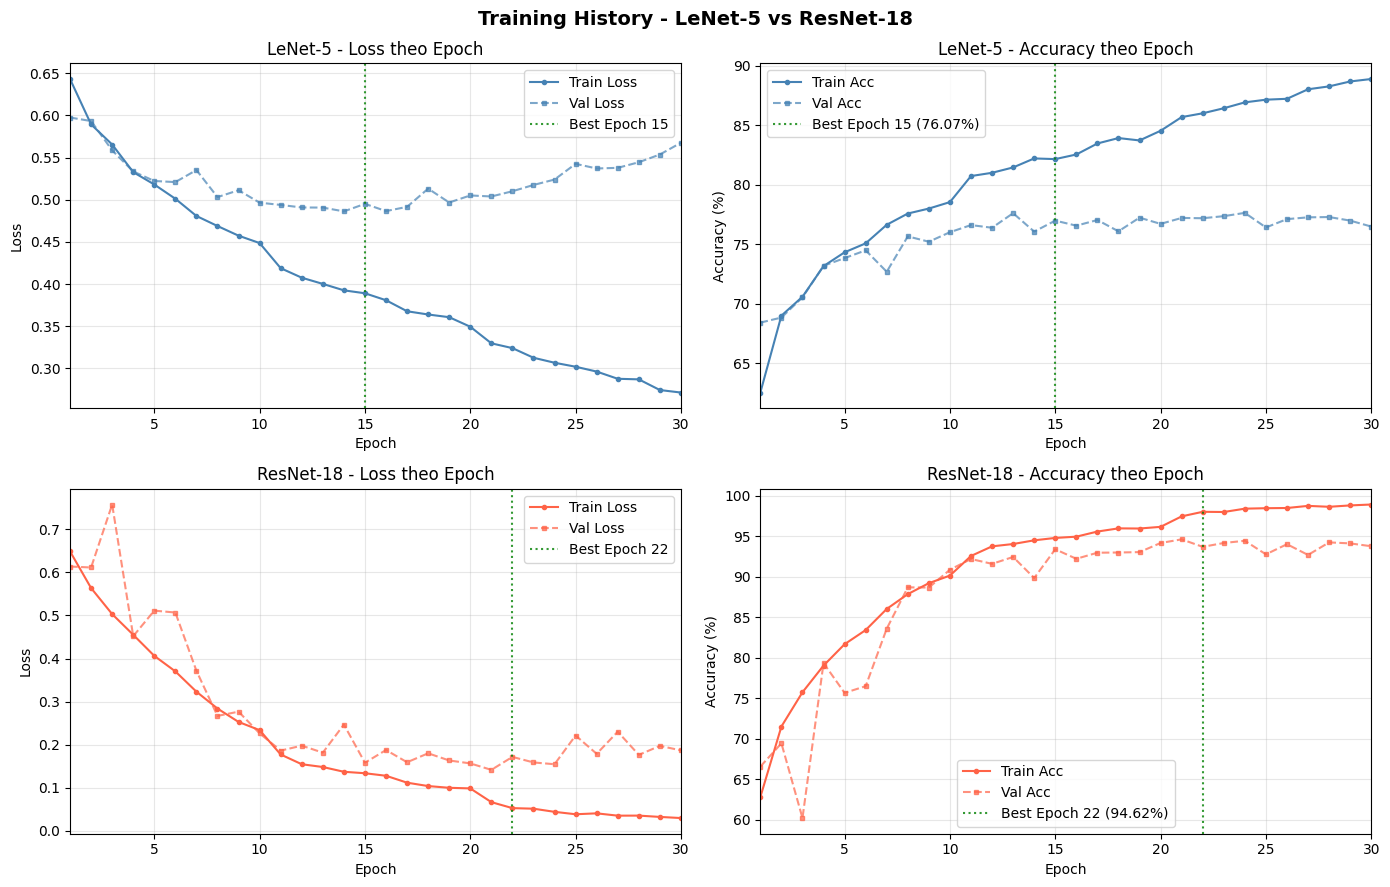

In [8]:

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("Training History - LeNet-5 vs ResNet-18", fontsize=14, fontweight="bold")

for row, (hist, name, color) in enumerate([
    (lenet_hist,  "LeNet-5",   "steelblue"),
    (resnet_hist, "ResNet-18", "tomato"),
]):
    epochs = range(1, len(hist["train_loss"]) + 1)

    # Loss
    ax = axes[row][0]
    ax.plot(epochs, hist["train_loss"], "-o", markersize=3,
            color=color, label="Train Loss")
    ax.plot(epochs, hist["val_loss"], "--s", markersize=3,
            color=color, alpha=0.7, label="Val Loss")

    # Đánh dấu epoch có validation loss nhỏ nhất
    best_epoch = hist.get("best_epoch")
    if best_epoch is not None:
        # JSON dùng epoch bắt đầu từ 0; biểu đồ bắt đầu từ 1
        best_epoch_plot = best_epoch + 1

        ax.axvline(
            best_epoch_plot,
            color="green",
            linestyle=":",
            alpha=0.8,
            label=f"Best Epoch {best_epoch_plot}"
        )

    ax.set(
        xlabel="Epoch",
        ylabel="Loss",
        title=name + " - Loss theo Epoch",
        xlim=(1, len(epochs))
    )
    ax.legend()
    ax.grid(alpha=0.3)

    # Accuracy
    ax = axes[row][1]
    ax.plot(epochs, hist["train_acc"], "-o", markersize=3,
            color=color, label="Train Acc")
    ax.plot(epochs, hist["val_acc"], "--s", markersize=3,
            color=color, alpha=0.7, label="Val Acc")

    if best_epoch is not None:
        ax.axvline(
            best_epoch_plot,
            color="green",
            linestyle=":",
            alpha=0.8,
            label=f"Best Epoch {best_epoch_plot} "
                  f"({hist['best_val_acc']:.2f}%)"
        )

    ax.set(
        xlabel="Epoch",
        ylabel="Accuracy (%)",
        title=name + " - Accuracy theo Epoch",
        xlim=(1, len(epochs))
    )
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


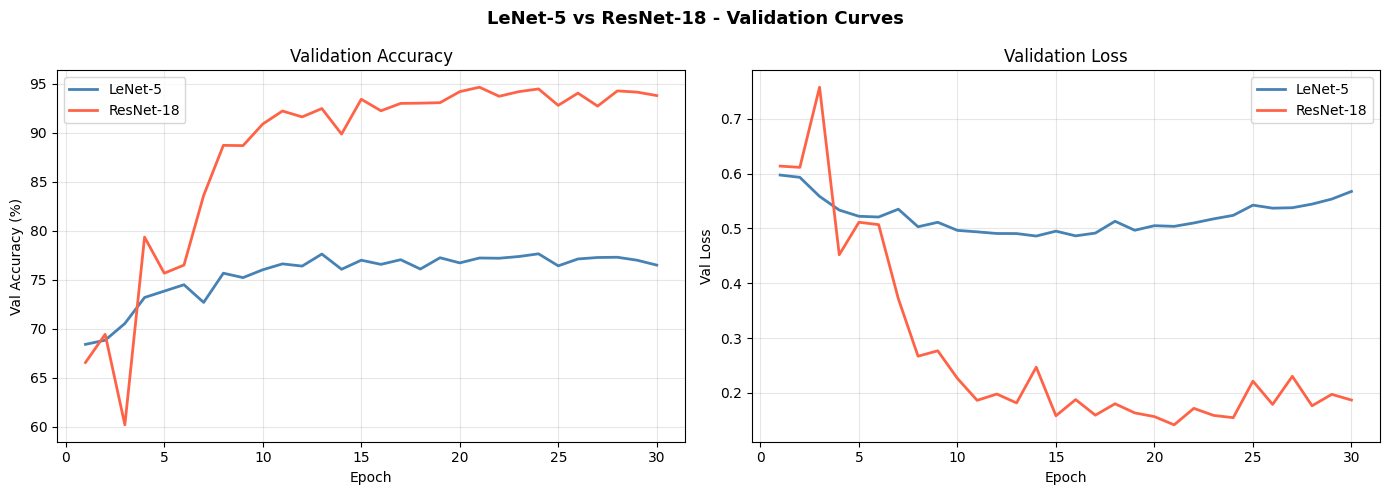

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("LeNet-5 vs ResNet-18 - Validation Curves", fontsize=13, fontweight="bold")

e_l = range(1, len(lenet_hist["val_acc"])  + 1)
e_r = range(1, len(resnet_hist["val_acc"]) + 1)

axes[0].plot(e_l, lenet_hist["val_acc"],  color="steelblue", lw=2, label="LeNet-5")
axes[0].plot(e_r, resnet_hist["val_acc"], color="tomato",    lw=2, label="ResNet-18")
axes[0].set(xlabel="Epoch", ylabel="Val Accuracy (%)", title="Validation Accuracy")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(e_l, lenet_hist["val_loss"],  color="steelblue", lw=2, label="LeNet-5")
axes[1].plot(e_r, resnet_hist["val_loss"], color="tomato",    lw=2, label="ResNet-18")
axes[1].set(xlabel="Epoch", ylabel="Val Loss", title="Validation Loss")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---
## 5. Test & So sanh ket qua <a id='5-compare'></a>

In [10]:
def load_model(name: str):
    _builders = {
        "lenet":   build_lenet,
        "resnet18": build_resnet18,
        "alexnet": build_alexnet,
        "vgg16":   build_vgg16,
    }
    builder = _builders[name]
    model   = builder(num_classes=2)
    ckpt_path = OUT_DIR / "metrics" / (name + "_best.pth")
    if not ckpt_path.exists():
        print(f"  [SKIP] Chua co checkpoint cho {name.upper()}")
        return None
    ckpt = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    model.to(DEVICE).eval()
    print(f"Loaded {name.upper()} best_epoch={ckpt['epoch']}")
    return model

trained_lenet   = load_model("lenet")
trained_resnet  = load_model("resnet18")
trained_alexnet = load_model("alexnet")
trained_vgg16   = load_model("vgg16")

C:\Users\tuanmit399\AppData\Local\Temp\ipykernel_3832\2887382165.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpt  = torch.load(OUT_DIR / "metrics" / (name + "_best.

Loaded LENET  best_epoch=14
Loaded RESNET18  best_epoch=21


In [11]:
# Chỉ đưa vào bảng những model đã có metrics
ALL_MODELS = [
    ("LeNet-5",   lenet_m),
    ("AlexNet",   alexnet_m),
    ("VGG-16",    vgg16_m),
    ("ResNet-18", resnet_m),
]
models = [(n, m) for n, m in ALL_MODELS if m is not None]

PALETTE_BG = ["#dbeafe", "#dcfce7", "#ffedd5", "#fef9c3"]
PALETTE_FG = ["#1e3a8a", "#14532d", "#9a3412", "#713f12"]
bg = {n: PALETTE_BG[i] for i, (n, _) in enumerate(models)}
fg = {n: PALETTE_FG[i] for i, (n, _) in enumerate(models)}

tbl_styles = [
    {"selector": "th", "props": [("text-align", "center"), ("font-weight", "bold")]},
    {"selector": "caption", "props": [("font-size", "14px"), ("margin-bottom", "8px")]},
]

overall = pd.DataFrame({
    "Metric": ["Accuracy (%)", "Macro Precision (%)", "Macro Recall (%)", "Macro F1 (%)", "N samples"],
    **{name: [m["accuracy"], m["macro_precision"], m["macro_recall"], m["macro_f1"], m["n_samples"]]
       for name, m in models},
}).set_index("Metric")

def bold_best_overall(row):
    if row.name == "N samples":
        return [""] * len(row)
    best = row.max()
    return ["font-weight: bold; text-decoration: underline" if v == best else "" for v in row]

styled = overall.style.apply(bold_best_overall, axis=1)
for name, _ in models:
    styled = styled.set_properties(
        subset=[name],
        **{"background-color": bg[name], "color": fg[name]}
    )
styled = (
    styled
    .format("{:.2f}")
    .format("{:.0f}", subset=pd.IndexSlice[["N samples"], :])
    .set_caption("Chi so tong the (Test Set)")
    .set_properties(**{"text-align": "center"})
    .set_table_styles(tbl_styles)
)
display(styled)

rows = []
for name, m in models:
    for cls in m["class_names"]:
        pc = m["per_class"][cls]
        rows.append({
            "Model": name, "Class": cls,
            "Precision (%)": pc["precision"],
            "Recall (%)":    pc["recall"],
            "F1-Score (%)":  pc["f1"],
            "Support":       pc["support"],
        })
df_cls = pd.DataFrame(rows)
metric_cols = ["Precision (%)", "Recall (%)", "F1-Score (%)"]

def bold_best_cls(col):
    best = df_cls.groupby("Class")[col.name].transform("max")
    return ["font-weight: bold; text-decoration: underline" if v == b else "" for v, b in zip(col, best)]

display(
    df_cls.style
    .apply(bold_best_cls, subset=metric_cols)
    .format({"Precision (%)": "{:.2f}", "Recall (%)": "{:.2f}", "F1-Score (%)": "{:.2f}", "Support": "{:d}"})
    .hide(axis="index")
    .set_caption("Ket qua theo tung class (Test Set)")
    .set_properties(**{"text-align": "center"})
    .set_table_styles(tbl_styles)
)

,LeNet-5,ResNet-18
Metric,,
Accuracy (%),76.74,95.06
Macro Precision (%),76.89,95.11
Macro Recall (%),76.74,95.06
Macro F1 (%),76.71,95.06
N samples,5000,5000


Model,Class,Precision (%),Recall (%),F1-Score (%),Support
LeNet-5,cats,74.92,80.40,77.56,2500
LeNet-5,dogs,78.85,73.08,75.86,2500
ResNet-18,cats,96.61,93.40,94.98,2500
ResNet-18,dogs,93.61,96.72,95.14,2500


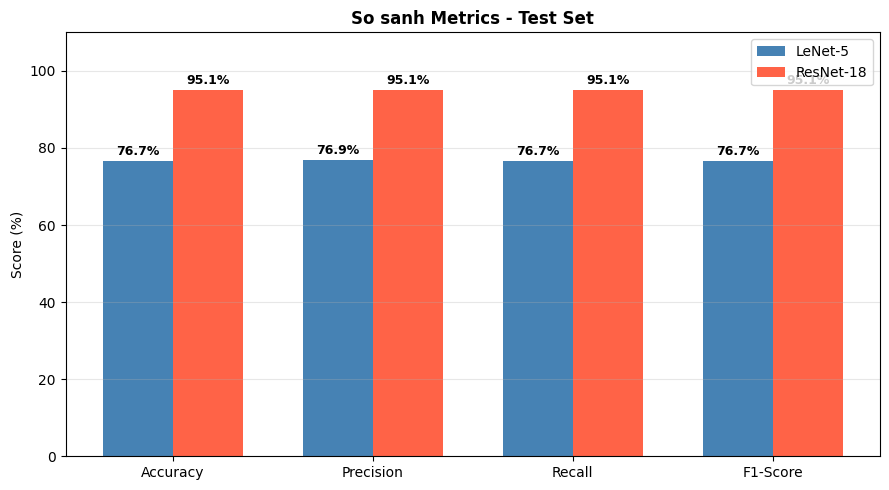

In [12]:
# Chỉ vẽ những model đã có metrics
ALL_MODELS = [
    ("LeNet-5",   lenet_m),
    ("AlexNet",   alexnet_m),
    ("VGG-16",    vgg16_m),
    ("ResNet-18", resnet_m),
]
models_avail = [(n, m) for n, m in ALL_MODELS if m is not None]

metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]
COLORS_GROUP = ["steelblue", "seagreen", "darkorange", "tomato"]

x = np.arange(len(metric_names))
n_models = len(models_avail)
w = 0.7 / n_models

fig, ax = plt.subplots(figsize=(11, 5))
for k, ((name, m), color) in enumerate(zip(models_avail, COLORS_GROUP)):
    scores = [m["accuracy"], m["macro_precision"], m["macro_recall"], m["macro_f1"]]
    offset = (k - n_models / 2 + 0.5) * w
    bars = ax.bar(x + offset, scores, w, color=color, label=name)
    for bar in bars:
        ax.annotate(
            f"{bar.get_height():.1f}%",
            xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4), textcoords="offset points",
            ha="center", fontsize=8, fontweight="bold",
        )

ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylabel("Score (%)")
ax.set_title("So sanh Metrics - Test Set", fontweight="bold")
ax.set_ylim(0, 115)
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

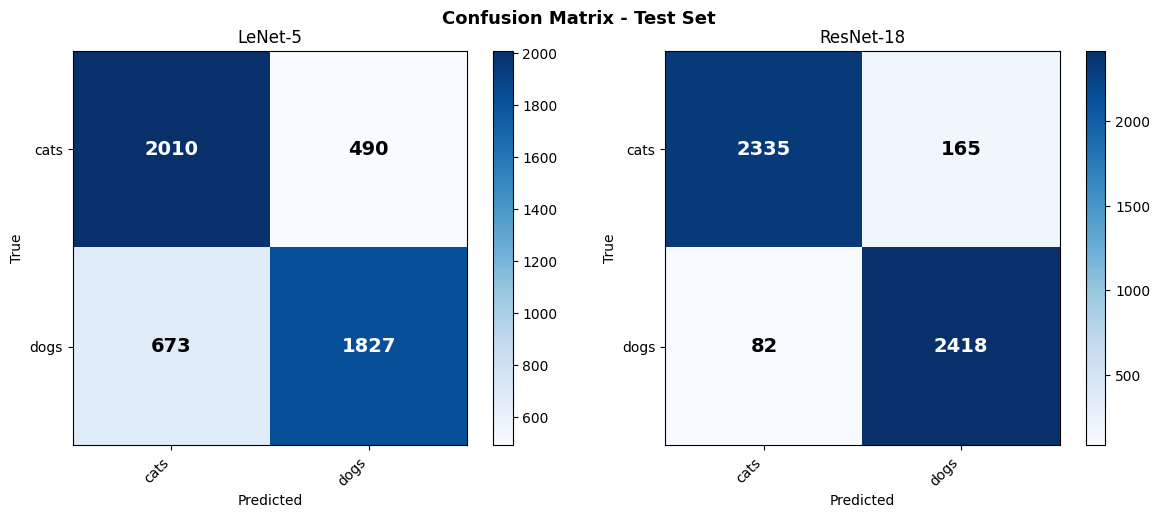

In [13]:
ALL_MODELS = [
    ("LeNet-5",   lenet_m),
    ("AlexNet",   alexnet_m),
    ("VGG-16",    vgg16_m),
    ("ResNet-18", resnet_m),
]
models_avail = [(n, m) for n, m in ALL_MODELS if m is not None]
class_names  = models_avail[0][1]["class_names"]

n_plots = len(models_avail)
fig, axes = plt.subplots(1, n_plots, figsize=(6 * n_plots, 5))
if n_plots == 1:
    axes = [axes]
fig.suptitle("Confusion Matrix - Test Set", fontsize=13, fontweight="bold")

for ax, (model_name, m) in zip(axes, models_avail):
    cm_arr = np.array(m["confusion_matrix"])
    im = ax.imshow(cm_arr, cmap="Blues")
    plt.colorbar(im, ax=ax)
    ax.set(
        xticks=range(len(class_names)), yticks=range(len(class_names)),
        xticklabels=class_names, yticklabels=class_names,
        xlabel="Predicted", ylabel="True", title=model_name,
    )
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    thresh = cm_arr.max() / 2
    for r in range(len(class_names)):
        for c in range(len(class_names)):
            ax.text(
                c, r, str(cm_arr[r, c]),
                ha="center", va="center", fontsize=14, fontweight="bold",
                color="white" if cm_arr[r, c] > thresh else "black",
            )

plt.tight_layout()
plt.show()

### Nhan xet

| | LeNet-5 | ResNet-18 |
|---|---|---|
| **Diem manh** | Nho gon, nhanh, de hieu | Accuracy cao, hoc duoc feature phuc tap |
| **Diem yeu** | Accuracy thap hon, khong scale tot | Nhieu tham so, chi phi tinh toan cao |
| **Phu hop** | Bai toan don gian, tai nguyen han che | Bai toan phan loai anh phuc tap |

**Ket luan:** ResNet-18 vuot troi LeNet-5 nho **Residual Connection** giup gradient khong bi triet
tieu khi lan truyen nguoc qua nhieu lop, va **Batch Normalization** giup training on dinh hon.

In [14]:
results = []

for name, cm in cms.items():
    # Cats = class 0
    tn_c, fp_c, fn_c, tp_c = cm.ravel()
    tpr_cats = tn_c / (tn_c + fp_c) if (tn_c + fp_c) > 0 else 0
    fpr_cats = fn_c / (fn_c + tp_c) if (fn_c + tp_c) > 0 else 0

    # Dogs = class 1
    tpr_dogs = tp_c / (tp_c + fn_c) if (tp_c + fn_c) > 0 else 0
    fpr_dogs = fp_c / (fp_c + tn_c) if (fp_c + tn_c) > 0 else 0

    results.extend([
        {
            "Model": name,
            "Class": "Cats",
            "TPR (%)": round(tpr_cats * 100, 2),
            "FPR (%)": round(fpr_cats * 100, 2)
        },
        {
            "Model": name,
            "Class": "Dogs",
            "TPR (%)": round(tpr_dogs * 100, 2),
            "FPR (%)": round(fpr_dogs * 100, 2)
        }
    ])

pd.DataFrame(results)

,Model,Class,TPR (%),FPR (%)
0,LeNet-5,Cats,80.40,26.92
1,LeNet-5,Dogs,73.08,19.60
2,ResNet-18,Cats,93.40,3.28
3,ResNet-18,Dogs,96.72,6.60


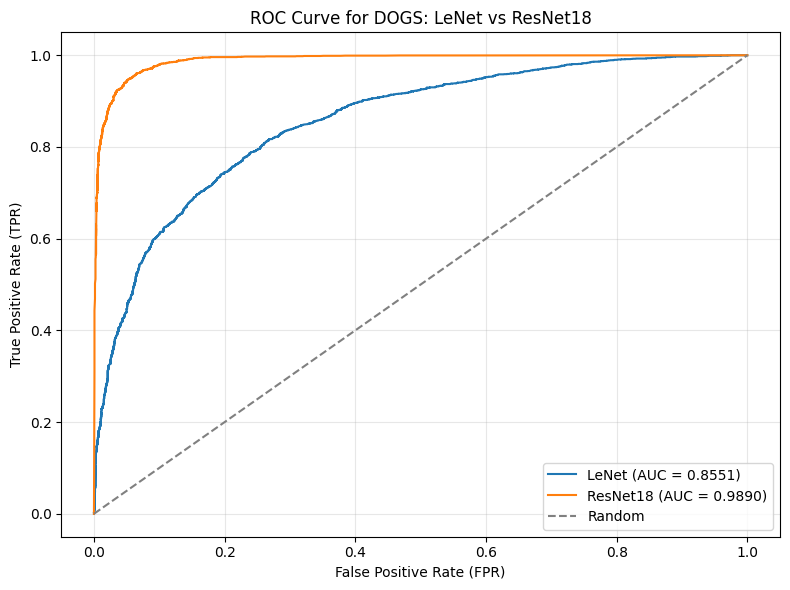

========== ROC/AUC FOR DOGS ==========
LeNet   AUC: 0.8551
ResNet18 AUC: 0.9890


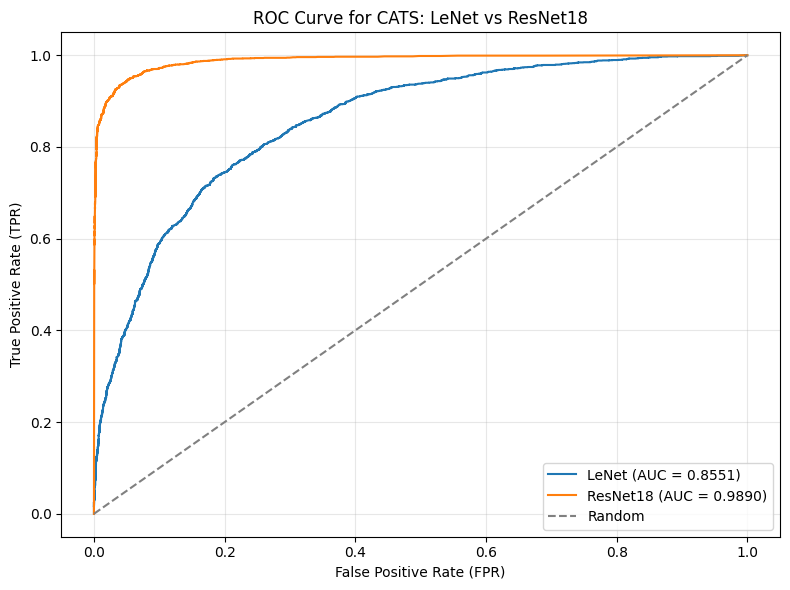


========== ROC/AUC FOR CATS ==========
LeNet   AUC: 0.8551
ResNet18 AUC: 0.9890


In [15]:
ds_test = CatsDogsDataset(DATA_DIR, "test")

t_lenet = get_transforms("lenet", "test", augment=False)
t_resnet = get_transforms("resnet18", "test", augment=False)

CLASS_LABELS = ["cats", "dogs"]


def get_scores(model, transform, target_class="dogs"):
    model.eval()
    y_true, y_score = [], []

    for path, label in ds_test.samples:
        result = predict_image(model, path, transform, DEVICE)

        pred = result["predicted_class"].lower()
        confidence = float(result["confidence"]) / 100

        # Xác suất thuộc lớp cần đánh giá
        if pred == target_class:
            prob_target = confidence
        else:
            prob_target = 1 - confidence

        # Nhãn thực tế: 1 nếu thuộc lớp cần đánh giá, 0 nếu không
        true_target = int(label == CLASS_LABELS.index(target_class))

        y_true.append(true_target)
        y_score.append(prob_target)

    return np.array(y_true), np.array(y_score)


def calculate_roc(y_true, y_score):
    thresholds = np.r_[
        np.inf, np.sort(np.unique(y_score))[::-1], -np.inf
    ]

    tpr, fpr = [], []

    for th in thresholds:
        pred = y_score >= th

        TP = np.sum((pred == 1) & (y_true == 1))
        FN = np.sum((pred == 0) & (y_true == 1))
        FP = np.sum((pred == 1) & (y_true == 0))
        TN = np.sum((pred == 0) & (y_true == 0))

        tpr.append(TP / (TP + FN) if TP + FN else 0)
        fpr.append(FP / (FP + TN) if FP + TN else 0)

    order = np.argsort(fpr)
    fpr = np.array(fpr)[order]
    tpr = np.array(tpr)[order]

    auc = np.trapezoid(tpr, fpr)

    return fpr, tpr, auc


# ==================================================
# 1. ROC và AUC cho lớp DOGS
# ==================================================

y_lenet_dog, s_lenet_dog = get_scores(
    trained_lenet, t_lenet, target_class="dogs"
)

y_resnet_dog, s_resnet_dog = get_scores(
    trained_resnet, t_resnet, target_class="dogs"
)

fpr_l_dog, tpr_l_dog, auc_l_dog = calculate_roc(
    y_lenet_dog, s_lenet_dog
)

fpr_r_dog, tpr_r_dog, auc_r_dog = calculate_roc(
    y_resnet_dog, s_resnet_dog
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_l_dog, tpr_l_dog,
    label=f"LeNet (AUC = {auc_l_dog:.4f})"
)

plt.plot(
    fpr_r_dog, tpr_r_dog,
    label=f"ResNet18 (AUC = {auc_r_dog:.4f})"
)

plt.plot([0, 1], [0, 1], "--", color="gray", label="Random")

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve for DOGS: LeNet vs ResNet18")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("========== ROC/AUC FOR DOGS ==========")
print(f"LeNet   AUC: {auc_l_dog:.4f}")
print(f"ResNet18 AUC: {auc_r_dog:.4f}")


# ==================================================
# 2. ROC và AUC cho lớp CATS
# ==================================================

y_lenet_cat, s_lenet_cat = get_scores(
    trained_lenet, t_lenet, target_class="cats"
)

y_resnet_cat, s_resnet_cat = get_scores(
    trained_resnet, t_resnet, target_class="cats"
)

fpr_l_cat, tpr_l_cat, auc_l_cat = calculate_roc(
    y_lenet_cat, s_lenet_cat
)

fpr_r_cat, tpr_r_cat, auc_r_cat = calculate_roc(
    y_resnet_cat, s_resnet_cat
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_l_cat, tpr_l_cat,
    label=f"LeNet (AUC = {auc_l_cat:.4f})"
)

plt.plot(
    fpr_r_cat, tpr_r_cat,
    label=f"ResNet18 (AUC = {auc_r_cat:.4f})"
)

plt.plot([0, 1], [0, 1], "--", color="gray", label="Random")

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve for CATS: LeNet vs ResNet18")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n========== ROC/AUC FOR CATS ==========")
print(f"LeNet   AUC: {auc_l_cat:.4f}")
print(f"ResNet18 AUC: {auc_r_cat:.4f}")

---
## 6. Demo Predict anh moi <a id='6-demo'></a>

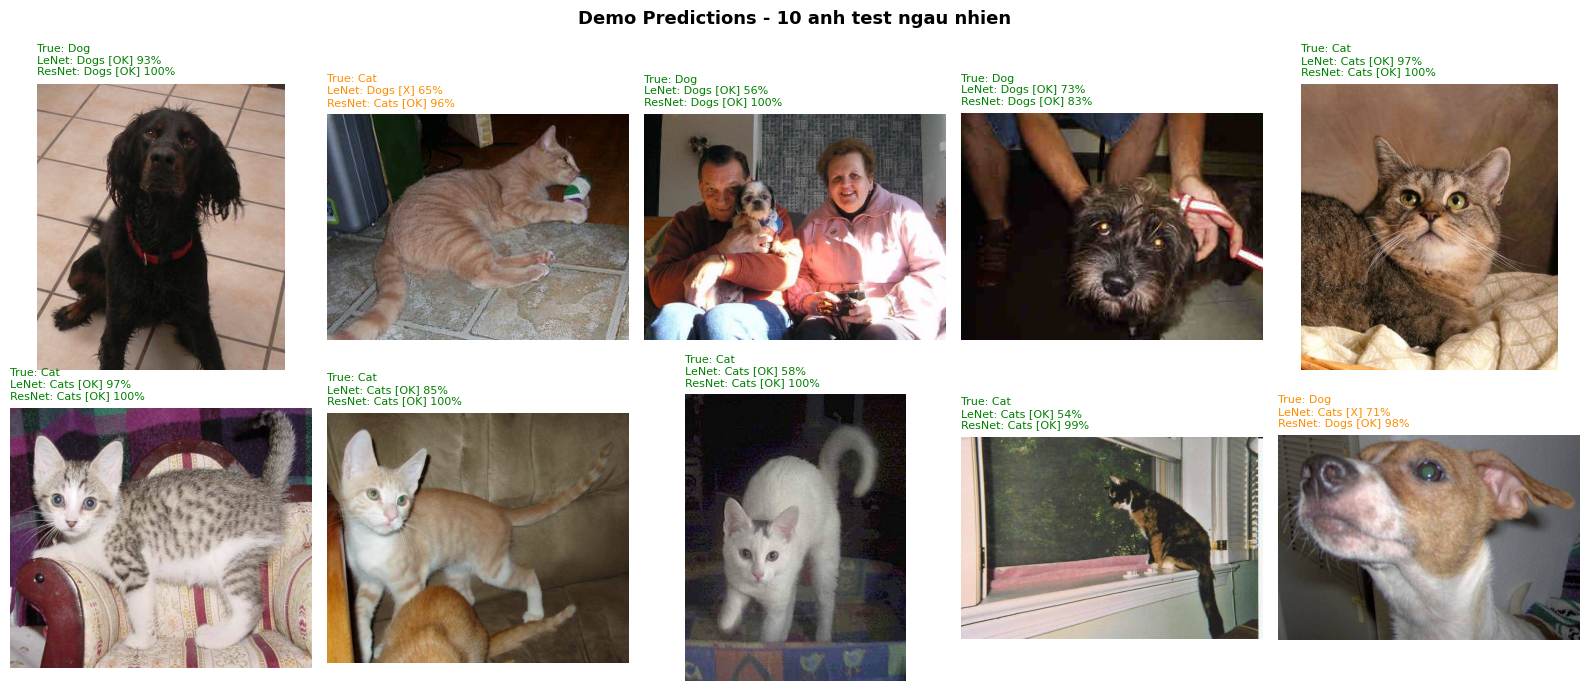

In [16]:
ds_test = CatsDogsDataset(DATA_DIR, "test")
sample_pairs = random.sample(ds_test.samples, 10)

transforms_map = {
    "lenet":    get_transforms("lenet",   "test", augment=False),
    "alexnet":  get_transforms("alexnet", "test", augment=False),
    "vgg16":    get_transforms("vgg16",   "test", augment=False),
    "resnet18": get_transforms("resnet18","test", augment=False),
}
trained_map = {
    "lenet":    trained_lenet,
    "alexnet":  trained_alexnet,
    "vgg16":    trained_vgg16,
    "resnet18": trained_resnet,
}
# Lọc các model đã train xong
trained_map = {k: v for k, v in trained_map.items() if v is not None}

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
CLASS_NAMES = ["cats", "dogs"]

for ax, (img_path, true_label) in zip(axes.ravel(), sample_pairs):
    img = Image.open(img_path).convert("RGB")
    ax.imshow(img)
    preds_str = []
    for name, model in trained_map.items():
        tf = transforms_map[name]
        with torch.no_grad():
            t   = tf(img).unsqueeze(0).to(DEVICE)
            idx = model(t).argmax(1).item()
        preds_str.append(f"{name}: {CLASS_NAMES[idx]}")
    true_cls = CLASS_NAMES[true_label]
    ax.set_title("True: " + true_cls + "\n" + "\n".join(preds_str), fontsize=7)
    ax.axis("off")

plt.tight_layout()
plt.show()

Dang predict: cat.0.jpg


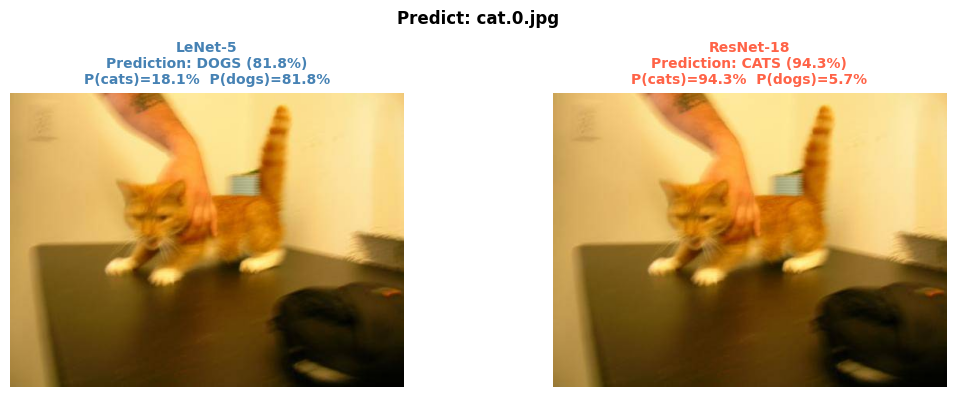

In [17]:
cat_images = sorted((DATA_DIR / "test" / "cats").glob("*.jpg"))
IMAGE_PATH = cat_images[0]   # <-- doi sang dog_images[i] tuy y
print("Dang predict:", IMAGE_PATH.name)

img = Image.open(IMAGE_PATH)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle("Predict: " + IMAGE_PATH.name, fontsize=12, fontweight="bold")

for ax, (name, model, tf) in zip(axes, [
    ("LeNet-5",   trained_lenet,  t_lenet),
    ("ResNet-18", trained_resnet, t_resnet),
]):
    res   = predict_image(model, IMAGE_PATH, tf, DEVICE)
    color = "steelblue" if "LeNet" in name else "tomato"
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(
        name + "\nPrediction: " + res["predicted_class"].upper() + " (" + str(round(res["confidence"], 1)) + "%)\n"
        "P(cats)=" + str(round(res["prob_cats"], 1)) + "%  P(dogs)=" + str(round(res["prob_dogs"], 1)) + "%",
        fontsize=10, color=color, fontweight="bold",
    )

plt.tight_layout()
plt.show()

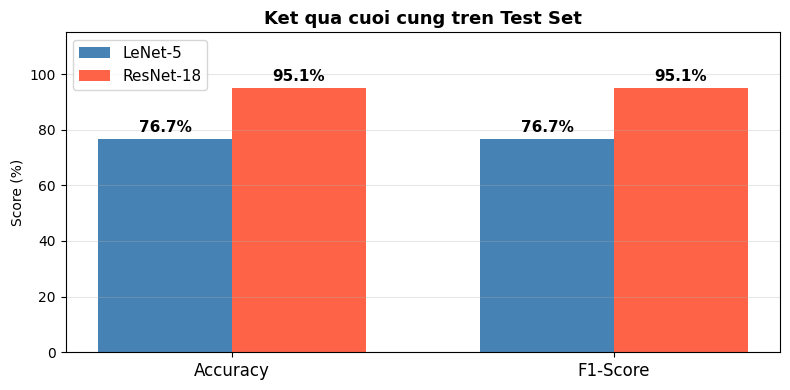

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
summary_metrics = ["Accuracy", "F1-Score"]
lenet_vals  = [lenet_m["accuracy"],  lenet_m["macro_f1"]]
resnet_vals = [resnet_m["accuracy"], resnet_m["macro_f1"]]
x = np.arange(len(summary_metrics))
w = 0.35
b1 = ax.bar(x - w/2, lenet_vals,  w, color="steelblue", label="LeNet-5")
b2 = ax.bar(x + w/2, resnet_vals, w, color="tomato",    label="ResNet-18")
for bar in list(b1) + list(b2):
    ax.annotate(
        str(round(bar.get_height(), 1)) + "%",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5), textcoords="offset points",
        ha="center", fontsize=11, fontweight="bold",
    )
ax.set_xticks(x)
ax.set_xticklabels(summary_metrics, fontsize=12)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 115)
ax.set_title("Ket qua cuoi cung tren Test Set", fontsize=13, fontweight="bold")
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()